In [55]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)
df= data.frame
df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [56]:
df.shape

(569, 31)

In [57]:
corr=df.corr()['target'].sort_values(ascending=False)
corr

target                     1.000000
smoothness error           0.067016
mean fractal dimension     0.012838
texture error              0.008303
symmetry error             0.006522
fractal dimension error   -0.077972
concavity error           -0.253730
compactness error         -0.292999
worst fractal dimension   -0.323872
mean symmetry             -0.330499
mean smoothness           -0.358560
concave points error      -0.408042
mean texture              -0.415185
worst symmetry            -0.416294
worst smoothness          -0.421465
worst texture             -0.456903
area error                -0.548236
perimeter error           -0.556141
radius error              -0.567134
worst compactness         -0.590998
mean compactness          -0.596534
worst concavity           -0.659610
mean concavity            -0.696360
mean area                 -0.708984
mean radius               -0.730029
worst area                -0.733825
mean perimeter            -0.742636
worst radius              -0

In [58]:
df.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'target'],
      dtype='str')

In [59]:
x = df[["smoothness error","mean fractal dimension","texture error","symmetry error","fractal dimension error"]]
y = df["target"]

In [60]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42, stratify=y)

In [61]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaler=scaler.fit_transform(x_train)
x_test_scaler=scaler.transform(x_test)

In [62]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train_scaler, y_train)
y_pred=model.predict(x_test_scaler)

In [63]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
print("Accuracy:",accuracy_score(y_test,y_pred))
print("Precision:",precision_score(y_test,y_pred))
print("Recall:",recall_score(y_test,y_pred))
print("F1-Score:",f1_score(y_test,y_pred))

Accuracy: 0.6403508771929824
Precision: 0.6371681415929203
Recall: 1.0
F1-Score: 0.7783783783783784


In [64]:
x=df.drop(columns=["target"])
y=df["target"]

In [65]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42, stratify=y)


In [66]:
scaler2=StandardScaler()
x_train_scaler2=scaler2.fit_transform(x_train)
x_test_scaler2=scaler2.transform(x_test)

In [67]:
model2=LogisticRegression()
model2.fit(x_train_scaler2, y_train)
y_pred2=model2.predict(x_test_scaler2)

In [68]:
print("Accuracy2:",accuracy_score(y_test,y_pred2))
print("Precision2:",precision_score(y_test,y_pred2))
print("Recall2:",recall_score(y_test,y_pred2))
print("F1-Score2:",f1_score(y_test,y_pred2))

Accuracy2: 0.9824561403508771
Precision2: 0.9861111111111112
Recall2: 0.9861111111111112
F1-Score2: 0.9861111111111112


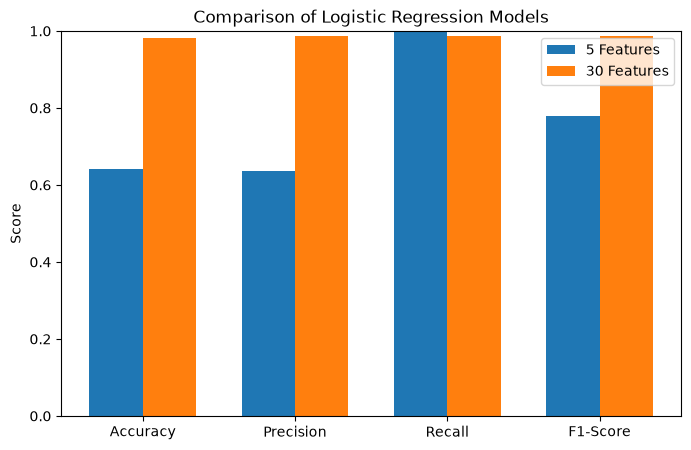

In [69]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
metrics=["Accuracy","Precision","Recall","F1-Score"]
model_scores=[accuracy_score(y_test,y_pred),precision_score(y_test,y_pred),recall_score(y_test,y_pred),f1_score(y_test,y_pred)]
model2_scores=[accuracy_score(y_test,y_pred2),precision_score(y_test,y_pred2),recall_score(y_test,y_pred2),f1_score(y_test,y_pred2)]
x=np.arange(len(metrics))
width=0.35
plt.figure(figsize=(8,5))
plt.bar(x-width/2,model_scores,width,label="5 Features")
plt.bar(x+width/2,model2_scores,width,label="30 Features")
plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0,1)
plt.title("Comparison of Logistic Regression Models")
plt.legend()
plt.show()


In [70]:
x=df.drop(columns=["target"])
y=df["target"]

In [71]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42, stratify=y)
scaler3=StandardScaler()
x_train_scaler3=scaler3.fit_transform(x_train)
x_test_scaler3=scaler3.transform(x_test)
model3=LogisticRegression()
model3.fit(x_train_scaler3, y_train)
y_pred3=model3.predict(x_test_scaler3)

In [72]:
model3.classes_

array([0, 1])

In [73]:
# تمرین دوم
probamalignant=model3.predict_proba(x_test_scaler3)
malignant_proba=probamalignant[:,0]
print(malignant_proba.shape)

(114,)


In [74]:
import numpy as np
threshold=0.5
y_pred_threshold=np.where(malignant_proba >= threshold, 0, 1)
y_pred_threshold

array([0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1])

In [75]:

print(y_test.shape)
print(y_pred_threshold.shape)
print(y_test[:5])
print(y_pred_threshold[:5])

(114,)
(114,)
256    0
428    1
501    0
363    1
564    0
Name: target, dtype: int64
[0 1 0 1 0]


In [76]:

precision=precision_score(y_test,y_pred_threshold,pos_label=0)
recall=recall_score(y_test,y_pred_threshold,pos_label=0)
print("Precision:",precision)
print("Recall:",recall)

Precision: 0.9761904761904762
Recall: 0.9761904761904762


In [77]:
thresholds=np.arange(0.05,1.0,0.05)
print(threshold)
print(type(threshold))

0.5
<class 'float'>


In [78]:
precisions = []
recalls = []

for threshold in thresholds:
    y_pred_threshold = np.where(malignant_proba >= threshold, 0, 1)

    p = precision_score(y_test, y_pred_threshold, pos_label=0)
    r = recall_score(y_test, y_pred_threshold, pos_label=0)

    precisions.append(p)
    recalls.append(r)

In [79]:
valid = np.array(precisions) > 0.90
best_index = np.argmax(np.array(recalls)[valid])

In [80]:
valid_indices = np.where(valid)[0]
best_index = valid_indices[np.argmax(np.array(recalls)[valid])]

In [81]:
best_threshold = thresholds[best_index]
best_precision = precisions[best_index]
best_recall = recalls[best_index]

print(best_threshold)
print(best_precision)
print(best_recall)

0.4
0.9111111111111111
0.9761904761904762


In [82]:
x = df.drop(columns=["target"])
y = df["target"]

In [83]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42, stratify=y)
scaler4=StandardScaler()
x_train_scaler4=scaler4.fit_transform(x_train)
x_test_scaler4=scaler4.transform(x_test)

In [84]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaler4, y_train)
y_pred_knn=knn.predict(x_test_scaler4)

In [85]:
print("Accuracy:",accuracy_score(y_test,y_pred_knn))

Accuracy: 0.956140350877193


In [86]:
k_values = range(1, 16)
cv_scores = []

In [87]:
from sklearn.model_selection import cross_val_score
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k,metric="manhattan")
    scores = cross_val_score(knn, x_train_scaler4, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

In [88]:
max(cv_scores)

np.float64(0.9714285714285715)

In [89]:
best_k = k_values[cv_scores.index(max(cv_scores))]
best_k

4

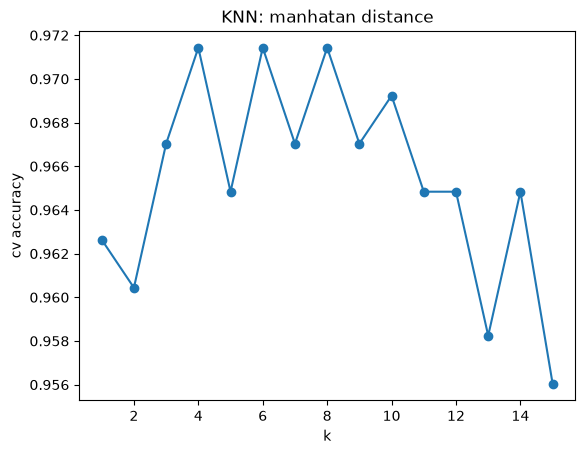

In [90]:
import matplotlib.pyplot as plt

plt.plot(k_values, cv_scores,marker='o')
plt.xlabel('k')
plt.ylabel('cv accuracy')
plt.title('KNN: manhatan distance')
plt.show()

In [91]:
from sklearn.tree import DecisionTreeClassifier
depths=[2,3,4,5,6,7,8,9,10,None]
cv_scores2=[]
for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_val_score(tree, x_train_scaler4, y_train, cv=5)
    cv_scores2.append(scores.mean())

In [92]:
max(cv_scores2)

np.float64(0.9384615384615385)

In [93]:
best_depth = depths[cv_scores2.index(max(cv_scores2))]
best_depth

4

In [94]:
best_tree=DecisionTreeClassifier(max_depth=best_depth, random_state=42)
best_tree.fit(x_train_scaler4, y_train)
y_pred_tree=best_tree.predict(x_test_scaler4)

In [95]:
accuracy_score(y_test,y_pred_tree)

0.9385964912280702

In [96]:

y_imbalanced = np.array([0] * 950 + [1] * 50)
rng=np.random.default_rng(42)
x_imbalanced = rng.normal(size=(1000, 2))


In [97]:
x_imbalanced[y_imbalanced == 1] += 2

In [98]:
x_train, x_test, y_train, y_test = train_test_split(x_imbalanced, y_imbalanced, test_size=0.2, random_state=42, stratify=y_imbalanced)

In [99]:
model_imbalanced = LogisticRegression()
model_imbalanced.fit(x_train, y_train)
y_pred_imbalanced = model_imbalanced.predict(x_test)


In [100]:
recall_imbalanced = recall_score(y_test, y_pred_imbalanced,pos_label=1)
recall_imbalanced

0.5

In [101]:
recall_dummy=recall_score(y_test, np.zeros(len(y_test)), pos_label=1)
recall_dummy

0.0

In [102]:
from sklearn.metrics import confusion_matrix
cm_logreg = confusion_matrix(y_test, y_pred_imbalanced)
cm_logreg

array([[189,   1],
       [  5,   5]])

In [103]:
cm_dummy = confusion_matrix(y_test, np.zeros(len(y_test)))
cm_dummy

array([[190,   0],
       [ 10,   0]])

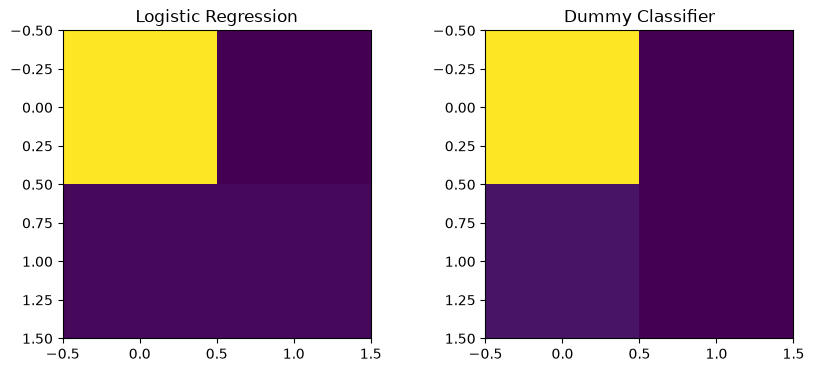

In [104]:
fig,axes=plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cm_logreg)
axes[0].set_title('Logistic Regression')
axes[1].imshow(cm_dummy)
axes[1].set_title('Dummy Classifier')
plt.show()

In [ ]:

X_toy = np.array([
    [1.0, 2.0], [1.5, 1.8], [1.2, 2.6], [2.0, 2.2], [0.8, 1.5],
    [4.5, 4.0], [5.0, 3.5], [4.2, 4.8], [5.5, 4.2], [4.8, 3.2],
])
y_toy = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])
query = np.array([3.0, 3.0])

distances = np.sqrt(((X_toy - query) ** 2).sum(axis=1))
order = np.argsort(distances)

k = 5
nearest_k_labels = y_toy[order[:k]]
vote = np.bincount(nearest_k_labels).argmax()

print("Votes among 3 nearest neighbors:", np.bincount(nearest_k_labels))
print("Predicted class:", vote)

Votes among 3 nearest neighbors: [3 2]
Predicted class: 0


In [107]:

X_toy = np.array([
    [1.0, 2.0], [1.5, 1.8], [1.2, 2.6], [2.0, 2.2], [0.8, 1.5],
    [4.5, 4.0], [5.0, 3.5], [4.2, 4.8], [5.5, 4.2], [4.8, 3.2],
])
y_toy = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])
query = np.array([3.0, 3.0])

distances = np.sqrt(((X_toy - query) ** 2).sum(axis=1))
order = np.argsort(distances)

k = 5
nearest_k_labels = y_toy[order[:k]]
vote = np.bincount(nearest_k_labels).argmax()

print("Votes among 3 nearest neighbors:", np.bincount(nearest_k_labels))
print("Predicted class:", vote)

Votes among 3 nearest neighbors: [3 2]
Predicted class: 0


In [108]:
import pandas as pd

tennis = pd.DataFrame({
    "Outlook":  ["Sunny", "Sunny", "Overcast", "Rain", "Rain", "Rain",
                 "Overcast", "Sunny", "Overcast", "Rain"],
    "Humidity": ["High", "High", "High", "High", "Normal", "Normal",
                 "Normal", "Normal", "Normal", "High"],
    "Wind":     ["Weak", "Strong", "Weak", "Weak", "Weak", "Strong",
                 "Strong", "Weak", "Weak", "Strong"],
    "Play":     ["No", "No", "Yes", "Yes", "Yes", "No",
                 "Yes", "Yes", "Yes", "No"],
})
tennis

,Outlook,Humidity,Wind,Play
0,Sunny,High,Weak,No
1,Sunny,High,Strong,No
2,Overcast,High,Weak,Yes
3,Rain,High,Weak,Yes
4,Rain,Normal,Weak,Yes
5,Rain,Normal,Strong,No
6,Overcast,Normal,Strong,Yes
7,Sunny,Normal,Weak,Yes
8,Overcast,Normal,Weak,Yes
9,Rain,High,Strong,No


In [109]:
tennis.loc[len(tennis)]= ["Sunny", "Normal", "Strong", "Yes"]
tennis

,Outlook,Humidity,Wind,Play
0,Sunny,High,Weak,No
1,Sunny,High,Strong,No
2,Overcast,High,Weak,Yes
3,Rain,High,Weak,Yes
4,Rain,Normal,Weak,Yes
5,Rain,Normal,Strong,No
6,Overcast,Normal,Strong,Yes
7,Sunny,Normal,Weak,Yes
8,Overcast,Normal,Weak,Yes
9,Rain,High,Strong,No


In [110]:
X_tennis = pd.get_dummies(tennis.drop(columns="Play"))
y_tennis = (tennis["Play"] == "Yes").astype(int)

In [111]:
tennis_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tennis_tree.fit(X_tennis, y_tennis)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

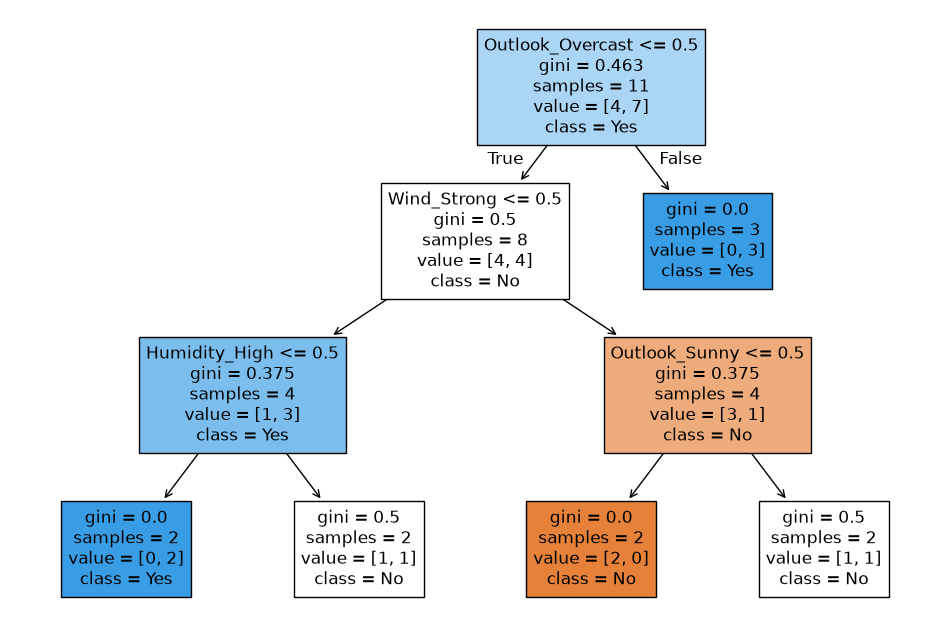

In [113]:
from sklearn.tree import plot_tree
plt.figure(figsize=(12, 8))
plot_tree(
    tennis_tree,
    feature_names=X_tennis.columns,
    class_names=["No", "Yes"],
    filled=True
)
plt.show()

In [115]:
from sklearn.datasets import load_wine
wine = load_wine(as_frame=True)
wine_df = wine.frame
wine_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [116]:
x = wine_df.drop(columns="target")
y = wine_df["target"]

In [119]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
scaler=StandardScaler()
x_train_scaler=scaler.fit_transform(x_train)
x_test_scaler=scaler.transform(x_test)

In [121]:
model_log = LogisticRegression()
model_log.fit(x_train_scaler, y_train)
model_knn=KNeighborsClassifier(n_neighbors=5)
model_knn.fit(x_train_scaler, y_train)
model_tree=DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(x_train_scaler, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [122]:
y_pred_log = model_log.predict(x_test_scaler)
y_pred_knn = model_knn.predict(x_test_scaler)
y_pred_tree = model_tree.predict(x_test_scaler)


In [124]:
accuracy_log = accuracy_score(y_test, y_pred_log)
accuracy_knn = accuracy_score(y_test, y_pred_knn)
accuracy_tree = accuracy_score(y_test, y_pred_tree)
print("Logistic Regression Accuracy:", accuracy_log)
print("KNN Accuracy:", accuracy_knn)
print("Decision Tree Accuracy:", accuracy_tree)

Logistic Regression Accuracy: 0.9722222222222222
KNN Accuracy: 0.9722222222222222
Decision Tree Accuracy: 0.9444444444444444


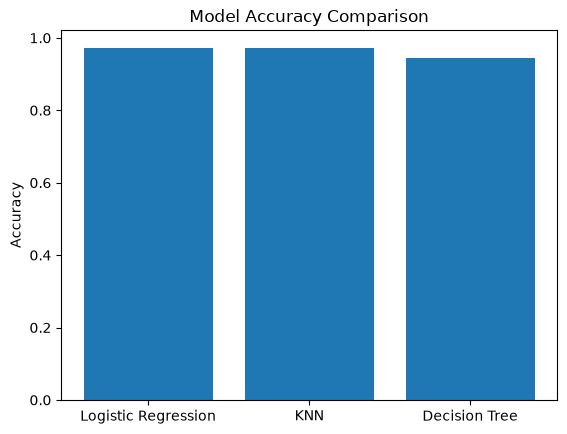

In [126]:
accuracyies= [accuracy_log, accuracy_knn, accuracy_tree]
model_names = ["Logistic Regression", "KNN", "Decision Tree"]
plt.bar(model_names, accuracyies)
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.show()